# ChessGPT — v1: Data pipeline and the bigram baseline

## The project
Can a language model learn to play chess **just by reading games**, without ever being told the rules?

We will train models that read chess games written as text, such as `e4 e5 Nf3 Nc6 Bb5 a6 ...`, and learn to predict the next move.
Nobody tells them how a knight moves, what check is, or that a pawn cannot move backwards. Everything must be inferred from millions of examples.

**The key metric** is objective: the **legal move rate**, i.e. the fraction of generated moves that are legal in the current position, verified with the `python-chess` library.

## Roadmap
| Version | Model | Question |
|---|---|---|
| **v1** | **Bigram** (next character depends only on the previous one) | How far can pure local statistics go? |
| v2 | MLP with a context window + embeddings | Does a few characters of context help? |
| v3 | RNN / LSTM | Can a recurrent memory track a whole game? |
| v4 | **GPT from scratch** (self-attention) | Does attention over the whole game make moves legal? |
| v5 | Move-level tokens, bigger GPT, **linear probes** | Has the model built an internal picture of the board? |
| v6 | Web app: **play against ChessGPT** | |

Every version uses the same data and the same evaluation, so the results are directly comparable, as in the animal project.

## What v1 does
1. **Download** real games from the Lichess open database.
2. **Parse** the PGN files and keep only the moves.
3. **Explore** the data: game lengths, openings, characters.
4. Build a **character-level vocabulary** and split games into train / validation / test.
5. Train the simplest language model, the **bigram**, in two ways: by **counting**, and as a **neural network** trained with gradient descent. They should agree.
6. Build the **evaluation harness** used by every later version: legal move rate on real positions, and self-play until the first illegal move.

## Requirements
Two extra libraries, besides PyTorch, NumPy and matplotlib:

```bash
pip install chess zstandard
```

- `chess` (python-chess): chess rules, move validation, board drawing.
- `zstandard`: decompresses the `.zst` files of the Lichess database.

In [1]:
# --- CORE LIBRARIES ---

# PyTorch: tensors, automatic gradients, neural networks.
import torch

# Functional operations: softmax, cross-entropy, one-hot encoding.
import torch.nn.functional as F

# Numerical computing: fast counting over millions of characters.
import numpy as np

# Plotting.
import matplotlib.pyplot as plt

# Logarithmic colour scale for heatmaps.
from matplotlib.colors import LogNorm

# python-chess: board representation, legal moves, SAN parsing (pip install chess).
import chess

# SVG drawings of chess boards.
import chess.svg

# Zstandard decompression for the Lichess .zst files (pip install zstandard).
import zstandard

# Display SVG images inside the notebook.
from IPython.display import SVG, display

# Counting occurrences (openings, characters).
from collections import Counter

# File and folder paths.
from pathlib import Path

# Text streams on top of binary streams (decompressed bytes -> lines of text).
import io

# Regular expressions: clean up the PGN move text.
import re

# Download files.
import urllib.request

# Measure execution time.
import time

# Python's random module: sampling positions for the evaluation.
import random

In [2]:
# --- DEVICE AND REPRODUCIBILITY ---

# Fastest device available: NVIDIA GPU, Apple Silicon GPU, or CPU.
if torch.cuda.is_available():

    # NVIDIA GPU.
    device = torch.device("cuda")

elif torch.backends.mps.is_available():

    # Apple Silicon GPU.
    device = torch.device("mps")

else:

    # CPU (fine for v1: the bigram model is tiny).
    device = torch.device("cpu")

# Seed for PyTorch (initialisation, sampling).
torch.manual_seed(42)

# Seed for Python's random module (choice of evaluation positions).
random.seed(42)

# Print the device.
print("Device:", device)

Device: mps


## Step 1 — The data: the Lichess open database

[Lichess](https://lichess.org) publishes **every rated game played on the site**, one file per month, in the public domain (**CC0** license).
We start with **January 2013**, the smallest month: about 120,000 games, a file of about 17 MB.

### The PGN format
Games are stored in **PGN** (Portable Game Notation): a block of headers followed by the move text.

```
[Event "Rated Classical game"]
[White "player1"]
[Black "player2"]
[Result "1-0"]
[WhiteElo "1639"]
[BlackElo "1403"]
[Termination "Normal"]

1. e4 e5 2. Nf3 Nc6 3. Bc4 Bc5 4. b4 Bxb4 5. c3 Ba5 ... 1-0
```

### SAN: Standard Algebraic Notation
Each move is written in **SAN**:

| Symbol | Meaning | Example |
|---|---|---|
| `a`–`h`, `1`–`8` | files (columns) and ranks (rows) of the destination square | `e4` = pawn to e4 |
| `K Q R B N` | king, queen, rook, bishop, knight (no letter = pawn) | `Nf3` = knight to f3 |
| `x` | capture | `Bxb4` = bishop captures on b4 |
| `+`, `#` | check, checkmate | `Qh5+`, `Qxf7#` |
| `O-O`, `O-O-O` | castling king-side, queen-side | |
| `=Q` | promotion | `e8=Q` |
| extra file/rank | disambiguation when two pieces can reach the square | `Nbd7`, `R1e2` |

**SAN depends on the position.** `Nf3` is legal only if a knight can reach f3. To write correct moves, the model has to know where the pieces are, and it only ever sees the list of previous moves. This is exactly what makes the task interesting.

In [3]:
# --- DOWNLOAD ONE MONTH OF LICHESS GAMES ---

# Folder for the chess data.
DATA_DIR = Path("data/lichess")

# Create it if needed (parents=True also creates "data/").
DATA_DIR.mkdir(parents=True, exist_ok=True)

# Month to download: January 2013, the smallest file (~17 MB, ~120k games).
MONTH = "2013-01"

# File name used by Lichess.
ZST_NAME = f"lichess_db_standard_rated_{MONTH}.pgn.zst"

# Local path of the compressed file.
ZST_PATH = DATA_DIR / ZST_NAME

# Download URL.
URL = f"https://database.lichess.org/standard/{ZST_NAME}"

# Download only if the file is not already there.
if not ZST_PATH.exists():

    # Tell the user what is happening.
    print(f"Downloading {URL} ...")

    # Start time.
    start = time.perf_counter()

    # urlretrieve downloads the URL and writes it to the given path.
    urllib.request.urlretrieve(URL, ZST_PATH)

    # Report time and size (1 MB = 1024 * 1024 bytes).
    print(f"Done in {time.perf_counter() - start:.0f}s")

# Size of the compressed file.
print(f"{ZST_PATH}: {ZST_PATH.stat().st_size / 1024**2:.1f} MB")

data/lichess/lichess_db_standard_rated_2013-01.pgn.zst: 16.9 MB


## Step 2 — Parsing: from PGN to clean move sequences

We read the compressed file as a **stream**: the bytes are decompressed on the fly and split into lines, so the full uncompressed file (about 90 MB) never has to sit on disk.

For each game:
1. **Headers** (`[Key "Value"]`) are collected; we use them to filter games.
2. The **move text** is cleaned:
   - remove comments in braces, `{ ... }` (some games contain engine evaluations);
   - remove move numbers (`1.`, `1...`);
   - remove the result (`1-0`, `0-1`, `1/2-1/2`, `*`);
   - collapse multiple spaces.
3. Games are **filtered**:
   - drop abandoned games (`Termination "Abandoned"`), which often stop after a few moves;
   - keep games with at least **20 plies**. A *ply* is one move by one player, so 20 plies = 10 full moves.

The result is one game per line, e.g. `e4 e5 Nf3 Nc6 Bb5 a6 Ba4 Nf6 ...`.
It is saved to `data`, so later versions can load it in a second.

In [4]:
# --- PARSE THE PGN STREAM ---

# Minimum number of plies (single moves) for a game to be kept.
MIN_PLIES = 20

# Output file: one cleaned game per line.
GAMES_PATH = DATA_DIR / f"games_{MONTH}.txt"

# Regular expression for a header line such as [WhiteElo "1639"]: captures the key and the value.
HEADER_RE = re.compile(r'^\[(\w+) "(.*)"\]$')

# Regular expression for comments in braces: { ... } (non-greedy, no nested braces in Lichess files).
COMMENT_RE = re.compile(r"\{[^}]*\}")

# Regular expression for move numbers: "12." or "12...".
MOVE_NUMBER_RE = re.compile(r"\d+\.(\.\.)?")

# Regular expression for the result token at the end of the move text.
RESULT_RE = re.compile(r"(1-0|0-1|1/2-1/2|\*)\s*$")


# Regular expression for move annotations such as "!", "?", "!?", "?!", "??" (Lichess adds them to analysed games).
ANNOTATION_RE = re.compile(r"[?!]+")

# Turn raw PGN move text into a clean space-separated list of SAN moves.
def clean_movetext(text):
    """'1. e4 e5 2. Nf3 { [%eval 0.2] } 2... Nc6 1-0' -> 'e4 e5 Nf3 Nc6'."""

    # Remove comments.
    text = COMMENT_RE.sub(" ", text)

    # Remove the result at the end.
    text = RESULT_RE.sub(" ", text)

    # Remove move numbers.
    text = MOVE_NUMBER_RE.sub(" ", text)

    # Remove move annotations (e.g. "Bxc6?!" -> "Bxc6").
    text = ANNOTATION_RE.sub("", text)

    # split() without arguments splits on any whitespace and drops empty pieces; join with single spaces.
    return " ".join(text.split())


# Parse only once: if the cleaned file already exists, just load it.
if not GAMES_PATH.exists():

    # Start time.
    start = time.perf_counter()

    # Cleaned games.
    games = []

    # Headers of the current game.
    headers = {}

    # Statistics about the filtering.
    stats = Counter()

    # Open the compressed file in binary mode.
    with open(ZST_PATH, "rb") as compressed:

        # Decompress on the fly: stream_reader returns a file-like object of decompressed bytes.
        reader = zstandard.ZstdDecompressor().stream_reader(compressed)

        # Wrap the bytes in a text stream to read line by line as UTF-8 strings.
        for line in io.TextIOWrapper(reader, encoding="utf-8"):

            # Remove the newline and surrounding spaces.
            line = line.strip()

            # Empty lines separate headers from move text: nothing to do.
            if not line:

                # Next line.
                continue

            # Is it a header line?
            match = HEADER_RE.match(line)

            # Header: store it.
            if match:

                # match.group(1) is the key, match.group(2) the value.
                headers[match.group(1)] = match.group(2)

                # Next line.
                continue

            # Otherwise it is the move text (one line per game in Lichess files): this completes a game.
            stats["games read"] += 1

            # Clean the move text into a list of moves.
            moves = clean_movetext(line).split()

            # Filter 1: abandoned games.
            if headers.get("Termination") == "Abandoned":

                # Count and skip.
                stats["abandoned"] += 1

            # Filter 2: too short.
            elif len(moves) < MIN_PLIES:

                # Count and skip.
                stats["too short"] += 1

            # Keep the game.
            else:

                # Store it as one space-separated string.
                games.append(" ".join(moves))

            # Reset the headers for the next game.
            headers = {}

    # Write one game per line.
    GAMES_PATH.write_text("\n".join(games), encoding="utf-8")

    # Report.
    print(f"Parsed in {time.perf_counter() - start:.0f}s: {dict(stats)}")

# Load the cleaned games (one per line).
games = GAMES_PATH.read_text(encoding="utf-8").split("\n")

# How many games we kept.
print(f"Games kept: {len(games):,}")

# Show the beginning of the first game.
print("Example:", games[0][:120], "...")

Games kept: 115,628
Example: e4 e6 d4 b6 a3 Bb7 Nc3 Nh6 Bxh6 gxh6 Be2 Qg5 Bg4 h5 Nf3 Qg6 Nh4 Qg5 Bxh5 Qxh4 Qf3 Kd8 Qxf7 Nc6 Qe8# ...


## Step 3 — Exploring the games

Before modelling anything, we look at the data:
- **Game length** in plies: how long are the sequences the model must handle?
- **Openings**: the first moves are highly repetitive (`e4`, `d4`...), so a model can learn them easily. The middle game is where things get hard.
- **Characters**: SAN uses a tiny alphabet of files, ranks, piece letters and a few symbols.
- **Distinct moves**: how many different SAN strings appear in the data.

Plies per game: mean 70.0, median 65, max 306
Total characters: 33,350,008 | characters per ply (incl. space): 4.14
Distinct moves (SAN strings): 7,443


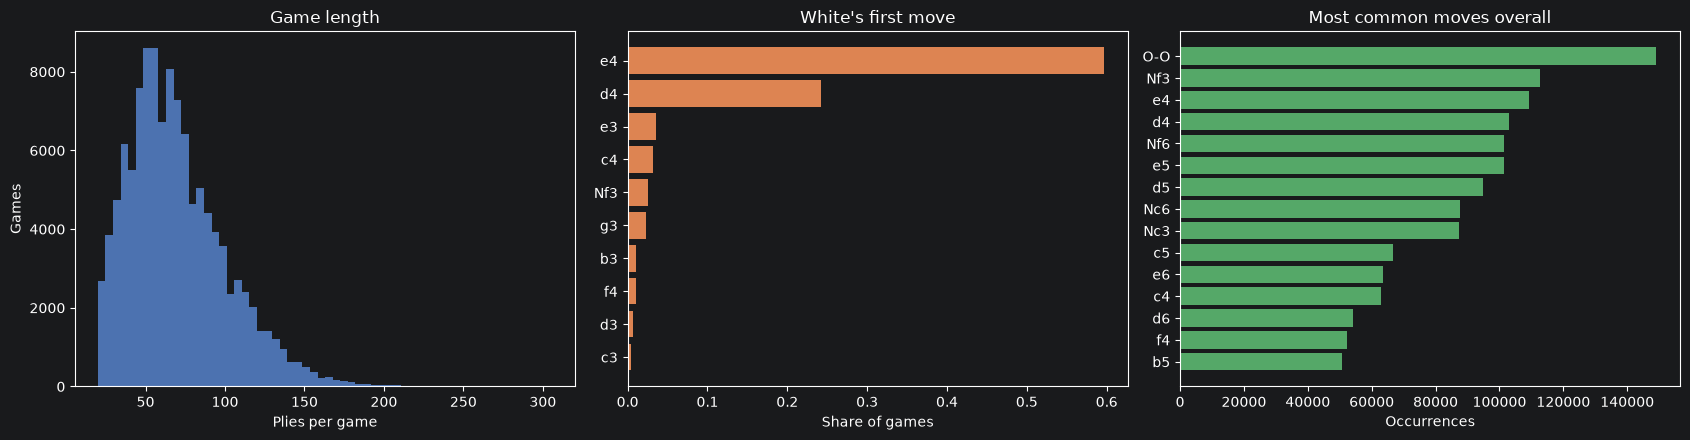

Most common first two plies: [('e4 e5', 30972), ('d4 d5', 13422), ('e4 c5', 11099), ('e4 e6', 7480), ('e4 d5', 5754)]


In [5]:
# --- GAME LENGTHS ---

# Number of plies of every game (number of space-separated moves).
lengths = np.array([len(g.split()) for g in games])

# Summary statistics.
print(f"Plies per game: mean {lengths.mean():.1f}, median {np.median(lengths):.0f}, max {lengths.max()}")

# Number of characters of every game.
char_lengths = np.array([len(g) for g in games])

# Total characters and average characters per ply.
print(f"Total characters: {char_lengths.sum():,} | characters per ply (incl. space): {(char_lengths.sum() + len(games)) / lengths.sum():.2f}")

# --- OPENINGS ---

# Counter of the first move of each game.
first_moves = Counter(g.split()[0] for g in games)

# Counter of the first two plies (White's and Black's first move).
first_two = Counter(" ".join(g.split()[:2]) for g in games)

# Counter of every single move in the data.
all_moves = Counter(m for g in games for m in g.split())

# Number of distinct SAN strings.
print(f"Distinct moves (SAN strings): {len(all_moves):,}")

# --- PLOTS ---

# Three panels side by side.
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(17, 4.5))

# Histogram of the game lengths, 60 bins.
ax1.hist(lengths, bins=60, color="#4C72B0")

# Axis labels.
ax1.set_xlabel("Plies per game")

# y-axis label.
ax1.set_ylabel("Games")

# Title.
ax1.set_title("Game length")

# The 10 most common first moves: most_common returns (move, count) pairs; zip(*...) splits them into two tuples.
names, counts = zip(*first_moves.most_common(10))

# Horizontal bar chart as a share of all games.
ax2.barh(names[::-1], np.array(counts[::-1]) / len(games), color="#DD8452")

# x-axis label.
ax2.set_xlabel("Share of games")

# Title.
ax2.set_title("White's first move")

# The 15 most common moves overall.
names, counts = zip(*all_moves.most_common(15))

# Horizontal bar chart.
ax3.barh(names[::-1], counts[::-1], color="#55A868")

# x-axis label.
ax3.set_xlabel("Occurrences")

# Title.
ax3.set_title("Most common moves overall")

# Avoid overlapping labels.
plt.tight_layout()

# Render the figure.
plt.show()

# The 5 most common two-ply openings.
print("Most common first two plies:", first_two.most_common(5))

## Step 4 — Character-level tokenization and data split

### Vocabulary
The model works on **characters**. The vocabulary $\mathcal{V}$ contains every character that appears in the games, plus one special token:

- `;` marks the **start and end of a game**. It never appears in SAN, so it is safe to use.

Each game becomes the string `;e4 e5 Nf3 Nc6 ... Kf2;`, and each character is mapped to an integer index:

$$
\texttt{stoi}: \mathcal{V} \to \{0, \dots, |\mathcal{V}| - 1\},
\qquad
\texttt{itos} = \texttt{stoi}^{-1}
$$

### Split
Games, not characters, are split randomly into **train (90%)**, **validation (5%)** and **test (5%)**. This way no game is partly in training and partly in evaluation.
- **Train**: fit the model.
- **Validation**: compare models and settings.
- **Test**: the final, untouched evaluation of the legal move rate.

### Fast encoding
Encoding about 30 million characters one by one in Python would be slow.
Instead we read the text as raw bytes (`np.frombuffer`) and translate all of them at once through a **lookup table** of 256 entries, one per possible byte value.

In [6]:
# --- VOCABULARY ---

# Special token for the start and end of a game.
SEP = ";"

# All characters used in the games, plus the separator, in sorted order.
chars = sorted(set("".join(games)) | {SEP})

# Vocabulary size.
V = len(chars)

# Character -> index.
stoi = {c: i for i, c in enumerate(chars)}

# Index -> character.
itos = {i: c for c, i in stoi.items()}

# Show the vocabulary; repr() makes the space visible as ' '.
print(f"Vocabulary ({V} characters):", " ".join(repr(c) for c in chars))

# --- TRAIN / VALIDATION / TEST SPLIT (by game) ---

# Shuffle a copy of the games with a fixed seed.
shuffled = games[:]

# random.Random(42) is a separate generator, so this shuffle is always the same.
random.Random(42).shuffle(shuffled)

# Number of validation games (5%).
n_val = len(shuffled) // 20

# Number of test games (5%).
n_test = len(shuffled) // 20

# First 5%: validation.
val_games = shuffled[:n_val]

# Next 5%: test.
test_games = shuffled[n_val:n_val + n_test]

# The remaining 90%: training.
train_games = shuffled[n_val + n_test:]

# Sizes.
print(f"Train: {len(train_games):,} games | Validation: {len(val_games):,} | Test: {len(test_games):,}")

# --- FAST ENCODING WITH A LOOKUP TABLE ---

# Lookup table: byte value -> vocabulary index (-1 for bytes that never occur).
lookup = np.full(256, -1, dtype=np.int64)

# Fill it: ord(c) is the byte value of the ASCII character c.
for c, i in stoi.items():

    # One entry per vocabulary character.
    lookup[ord(c)] = i


# Turn a list of games into one long array of indices: ";game1;game2;...;gameN;".
def encode_games(game_list):
    """Concatenate games separated by ';' and return an int64 NumPy array of vocabulary indices."""

    # One long string; each game is preceded and followed by the separator.
    text = SEP + SEP.join(game_list) + SEP

    # Raw bytes as an array of uint8, translated in one shot through the lookup table.
    ids = lookup[np.frombuffer(text.encode("ascii"), dtype=np.uint8)]

    # Every character must be in the vocabulary.
    assert (ids >= 0).all()

    # Return the indices.
    return ids


# Encode the three splits.
train_ids = encode_games(train_games)

# Validation indices.
val_ids = encode_games(val_games)

# Test indices.
test_ids = encode_games(test_games)

# Sizes in characters.
print(f"Characters — train: {len(train_ids):,} | validation: {len(val_ids):,} | test: {len(test_ids):,}")

# Decode back the first 40 characters, to check the encoding.
print("Decoded check:", "".join(itos[i] for i in train_ids[:40]))

Vocabulary (29 characters): ' ' '#' '+' '-' '1' '2' '3' '4' '5' '6' '7' '8' ';' '=' 'B' 'K' 'N' 'O' 'Q' 'R' 'a' 'b' 'c' 'd' 'e' 'f' 'g' 'h' 'x'
Train: 104,066 games | Validation: 5,781 | Test: 5,781
Characters — train: 30,128,102 | validation: 1,659,962 | test: 1,677,575
Decoded check: ;d4 d5 e4 dxe4 Nc3 Bf5 g4 Bg6 Nh3 a6 Nf4


## Step 5 — The bigram model, by counting

A **language model** assigns a probability to the next character given the previous ones. The **bigram** model is the simplest: it looks only at the **last character**.

$$
P(c_{t+1} \mid c_1, \dots, c_t) \approx P(c_{t+1} \mid c_t)
$$

### Estimation by counting
Count how often each pair $(a, b)$ appears in the training text, $N(a, b)$, and normalise each row.
**Laplace smoothing** ($\alpha = 1$) adds one fake occurrence to every pair, so no probability is exactly zero:

$$
P(b \mid a) = \frac{N(a, b) + \alpha}{\sum_{b'} N(a, b') + \alpha\, |\mathcal{V}|}
$$

Counting all pairs at once: each pair $(a, b)$ is turned into one integer $a \cdot |\mathcal{V}| + b$, and `np.bincount` counts the occurrences of every integer.

### Evaluation: negative log-likelihood, perplexity, bits per character
On the validation text $c_1, \dots, c_N$:

$$
\text{NLL} = -\frac{1}{N - 1} \sum_{t=1}^{N-1} \ln P(c_{t+1} \mid c_t),
\qquad
\text{perplexity} = e^{\text{NLL}},
\qquad
\text{bits per char} = \frac{\text{NLL}}{\ln 2}
$$

- **Perplexity** is the "effective number of choices" per character: a perplexity of 5 means the model is as uncertain as if it chose uniformly among 5 characters.
- **Bits per character (bpc)** is the average number of bits needed to encode each character with the model, the standard way to compare character-level models.
- **Reference:** a uniform guess over $|\mathcal{V}|$ characters has perplexity $|\mathcal{V}|$ and $\log_2 |\mathcal{V}|$ bits per character.

These are the same numbers we will track in every version.

model                      NLL  perplexity  bits/char
uniform guess            3.367       29.00      4.858
bigram (counting)        1.685        5.39      2.430


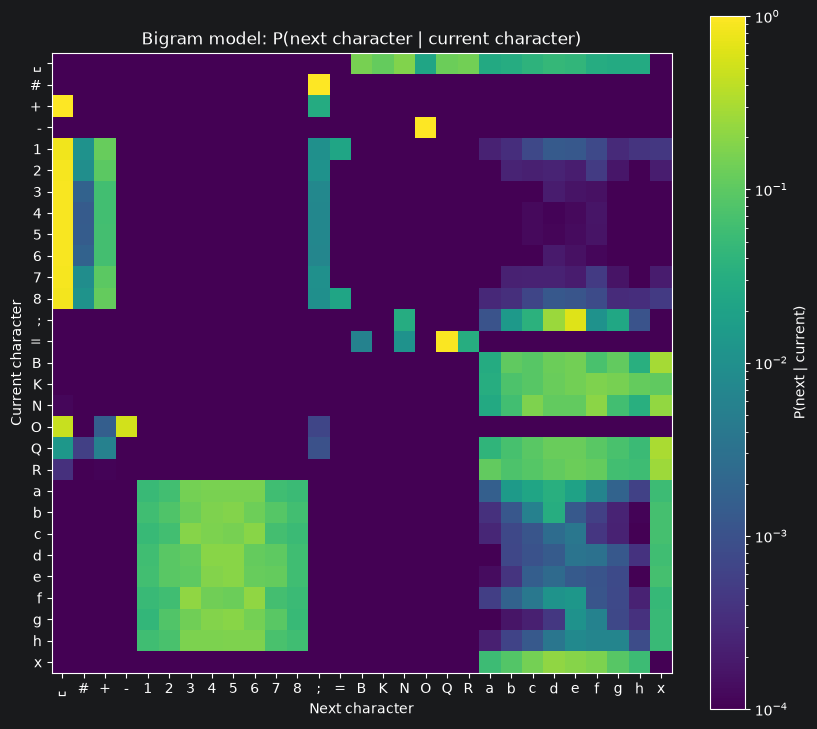

In [7]:
# --- COUNT ALL CHARACTER PAIRS IN THE TRAINING TEXT ---

# Each pair (a, b) becomes the single integer a * V + b; bincount counts every integer from 0 to V*V - 1.
pair_codes = train_ids[:-1] * V + train_ids[1:]

# Counts as a V x V matrix: row = current character a, column = next character b.
counts = np.bincount(pair_codes, minlength=V * V).reshape(V, V)

# Laplace smoothing constant.
ALPHA = 1.0

# Smoothed conditional probabilities: each row is divided by its total (keepdims keeps the shape (V, 1) for broadcasting).
P_count = (counts + ALPHA) / (counts + ALPHA).sum(axis=1, keepdims=True)


# NLL of a bigram probability matrix on an encoded text.
def bigram_nll(P, ids):
    """Average negative log-likelihood (natural log) of each next character given the previous one."""

    # P[ids[:-1], ids[1:]] picks, for every position t, the probability of the actual next character.
    return -np.log(P[ids[:-1], ids[1:]]).mean()


# Validation NLL of the counting model.
nll_count = bigram_nll(P_count, val_ids)

# Header.
print(f"{'model':<22}{'NLL':>8}{'perplexity':>12}{'bits/char':>11}")

# Uniform baseline: NLL = ln(V).
print(f"{'uniform guess':<22}{np.log(V):>8.3f}{V:>12.2f}{np.log2(V):>11.3f}")

# Bigram by counting.
print(f"{'bigram (counting)':<22}{nll_count:>8.3f}{np.exp(nll_count):>12.2f}{nll_count / np.log(2):>11.3f}")

# --- HEATMAP OF THE BIGRAM PROBABILITIES ---

# Square figure.
fig, ax = plt.subplots(figsize=(10, 9))

# Each cell = P(next | current); a logarithmic colour scale (LogNorm) makes small probabilities visible too.
im = ax.imshow(P_count, cmap="viridis", norm=LogNorm(vmin=1e-4, vmax=1))

# Colour bar.
fig.colorbar(im, ax=ax, label="P(next | current)")

# Tick labels: the characters; the space is shown as "␣" to be visible.
labels = ["␣" if c == " " else c for c in chars]

# Column labels = next character.
ax.set_xticks(range(V), labels)

# Row labels = current character.
ax.set_yticks(range(V), labels)

# Axis titles.
ax.set_xlabel("Next character")

# y-axis title.
ax.set_ylabel("Current character")

# Title.
ax.set_title("Bigram model: P(next character | current character)")

# Render the figure.
plt.show()

## Step 6 — The same bigram as a neural network

The bigram can also be written as the simplest possible neural network.
1. The current character $a$ is a **one-hot** vector $x \in \{0, 1\}^{|\mathcal{V}|}$.
2. A weight matrix $W \in \mathbb{R}^{|\mathcal{V}| \times |\mathcal{V}|}$ turns it into logits.
3. A softmax turns the logits into probabilities.

$$
z = x^\top W = W_{a,:},
\qquad
P(b \mid a) = \operatorname{softmax}(z)_b = \frac{e^{W_{a b}}}{\sum_{b'} e^{W_{a b'}}}
$$

Multiplying a one-hot vector by $W$ simply **selects row $a$**, so in code we write `W[a]`.

We train $W$ by minimising the cross-entropy, i.e. the NLL, with gradient descent, exactly as for the animal classifier.
At the optimum, $\operatorname{softmax}(W_{a,:})$ equals the empirical frequencies, so **the neural network must rediscover the counting solution**.
This is the bridge between classical statistics and neural networks, and the starting point for every later model: v2–v5 only replace "row $a$ of $W$" with something smarter.

Training uses **mini-batches** of 65,536 random character pairs and Adam.

model                      NLL  perplexity  bits/char
bigram (counting)        1.685        5.39      2.430
bigram (neural)          1.686        5.40      2.432
Max |P_neural - P_count| over observed pairs: 0.0204


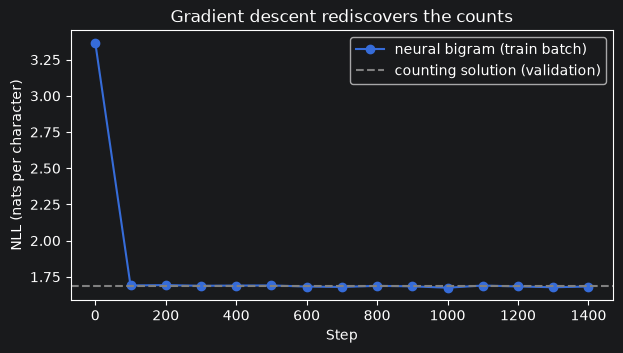

In [8]:
# --- TRAINING DATA AS TENSORS ---

# Current characters (inputs), on the device.
x_train = torch.tensor(train_ids[:-1], device=device)

# Next characters (targets), on the device.
y_train = torch.tensor(train_ids[1:], device=device)

# Validation inputs.
x_val = torch.tensor(val_ids[:-1], device=device)

# Validation targets.
y_val = torch.tensor(val_ids[1:], device=device)

# --- THE NEURAL BIGRAM: ONE WEIGHT MATRIX ---

# V x V weights, small random start; requires_grad=True asks PyTorch to compute gradients for it.
W = (0.01 * torch.randn(V, V, device=device)).requires_grad_()

# Adam optimiser with a fairly large learning rate (the problem is tiny and convex).
optimizer = torch.optim.Adam([W], lr=0.1)

# Mini-batch size.
BATCH = 65_536

# Number of training steps.
STEPS = 1500

# Training loss every 100 steps, for the plot.
losses = []

# Training loop.
for step in range(STEPS):

    # Random positions in the training text.
    idx = torch.randint(0, len(x_train), (BATCH,), device=device)

    # Logits: row W[a] for every current character a in the batch.
    logits = W[x_train[idx]]

    # Cross-entropy with the true next characters (= average NLL).
    loss = F.cross_entropy(logits, y_train[idx])

    # Reset gradients.
    optimizer.zero_grad()

    # Backpropagation.
    loss.backward()

    # Update W.
    optimizer.step()

    # Record the loss every 100 steps.
    if step % 100 == 0:

        # Store it as a Python number.
        losses.append(loss.item())

# --- EVALUATION ---

# No gradients needed.
with torch.no_grad():

    # Validation NLL of the neural bigram.
    nll_neural = F.cross_entropy(W[x_val], y_val).item()

    # Probability matrix of the neural bigram, as a NumPy array on the CPU.
    P_neural = F.softmax(W, dim=1).cpu().numpy()

# Compare the two models.
print(f"{'model':<22}{'NLL':>8}{'perplexity':>12}{'bits/char':>11}")

# Counting.
print(f"{'bigram (counting)':<22}{nll_count:>8.3f}{np.exp(nll_count):>12.2f}{nll_count / np.log(2):>11.3f}")

# Neural.
print(f"{'bigram (neural)':<22}{nll_neural:>8.3f}{np.exp(nll_neural):>12.2f}{nll_neural / np.log(2):>11.3f}")

# Largest difference between the two probability tables, restricted to pairs that actually occur in training.
occurring = counts > 0

# Report it.
print(f"Max |P_neural - P_count| over observed pairs: {np.abs(P_neural - P_count)[occurring].max():.4f}")

# --- TRAINING CURVE ---

# Small panel.
fig, ax = plt.subplots(figsize=(7, 3.5))

# Training loss every 100 steps.
ax.plot(range(0, STEPS, 100), losses, marker="o", label="neural bigram (train batch)")

# The counting solution as a reference line.
ax.axhline(nll_count, linestyle="--", color="gray", label="counting solution (validation)")

# Axis labels.
ax.set_xlabel("Step")

# y-axis label.
ax.set_ylabel("NLL (nats per character)")

# Title.
ax.set_title("Gradient descent rediscovers the counts")

# Legend.
ax.legend()

# Render the figure.
plt.show()

## Step 7 — Generating games

To **generate**, we start from `;` and repeatedly:
1. compute the distribution of the next character, $P(\cdot \mid c_t)$;
2. **sample** one character from it;
3. append it, and continue until the model emits `;` (end of game).

### Temperature
As in the calibration notebook of the animal project, logits can be divided by a temperature $\tau$ before the softmax. For a probability table this is equivalent to raising each probability to the power $1/\tau$ and renormalising:

$$
P_\tau(b \mid a) = \frac{P(b \mid a)^{1/\tau}}{\sum_{b'} P(b' \mid a)^{1/\tau}}
$$

- $\tau < 1$: more conservative; the most likely characters dominate.
- $\tau > 1$: more random.

### A common interface for every model
Every model in this project will expose the same function, `next_char_probs(context)`: given the list of characters generated so far (as indices), it returns the probability of each possible next character.
The bigram simply ignores everything except the last character. Generation and evaluation code written against this interface works unchanged for the MLP, the LSTM and the GPT of later versions.

In [9]:
# --- COMMON INTERFACE: NEXT-CHARACTER DISTRIBUTION ---

# The bigram looks only at the last character of the context.
def bigram_next_char_probs(context):
    """context: list of vocabulary indices generated so far. Returns a NumPy array of V probabilities."""

    # Row of the probability table for the last character.
    return P_count[context[-1]]


# Sample one index from a probability vector, with temperature.
def sample_from(probs, temperature=1.0):
    """Return a random index drawn from `probs` sharpened (T < 1) or flattened (T > 1) by the temperature."""

    # p^(1/T): equivalent to dividing the logits by T.
    p = probs ** (1.0 / temperature)

    # Renormalise so the probabilities sum to 1.
    p = p / p.sum()

    # np.random.choice draws one index with these probabilities.
    return np.random.choice(len(p), p=p)


# Generate a whole game as text.
def generate_game(next_char_probs, temperature=1.0, max_chars=1500):
    """Start from ';' and sample characters until the model emits ';' or max_chars is reached."""

    # The context starts with the start-of-game token.
    context = [stoi[SEP]]

    # Generate one character at a time.
    for _ in range(max_chars):

        # Sample the next character.
        nxt = sample_from(next_char_probs(context), temperature)

        # End-of-game token: stop.
        if nxt == stoi[SEP]:

            # Leave the loop.
            break

        # Append it to the context.
        context.append(nxt)

    # Decode everything after the initial ';'.
    return "".join(itos[i] for i in context[1:])


# Fixed NumPy seed, so the samples are reproducible.
np.random.seed(0)

# Three games at temperature 1.
for k in range(3):

    # Print the first 150 characters of each generated game.
    print(f"Sample {k + 1}: {generate_game(bigram_next_char_probs)[:150]}\n")

Sample 1: e6 Qe6 exd7 Qxb2 d7 h7 b2 Bxe4 b5 Bg5 f6 Ng2 Rc3 Nf4+ Kc6 Qd3 Rb3 c2 Bxdxe6 Nc3 Ne2 Qd5 Qxd6 Rd3 Bxa6 axc5 Qcxd7 Nxd8 e6 Qxe4 Bd6 Re2 Qg5 Re8 Nxf6 f6

Sample 2: d7 Rb8 Qe2 O-O-O Ng3 Bc1 Kec6 Kf5 f6 Rh4 Kcxf5 Kb5 Rd3 Bh4 exc6 Bxd4 d5 Nxcxe3+ Kd5 Ke4 Nf7 Qc6 Qc3 Nxf6 Bf5+ Kb1+ b4 Bexg4+ ge7 e4 Ra4 h5 Rd2 Kf3 dxh

Sample 3: g2+ O-O-O Be1 Re2 Ncxc6 Qfxd7 Nxe2 b6 Kg5 gxg4 Re1 Qxf6 c5 Ra2 h3 Bd4+ Na8 Bxb8 Nxexe2#



## Step 8 — The evaluation harness: is the chess legal?

Perplexity tells us how well a model predicts **characters**. What we really care about is whether it writes **legal chess**.
We measure it in two complementary ways, with `python-chess` as the referee.

### 1. Next-move legality on real positions
- Take 1,000 random positions from the **test games**: a game and a random cut point $k$.
- Give the model the real first $k$ moves as context.
- Let it generate the next move: characters until a space.
- Check whether that move is legal on the real board after those $k$ moves.

$$
\text{legal move rate} = \frac{1}{M} \sum_{i=1}^{M} \mathbb{1}\big[\hat{m}_i \in \text{LegalMoves}(\text{board}_i)\big]
$$

We also break the rate down by **game phase**, i.e. by the value of $k$. Openings are repetitive, so they should be easier than the middle game.

### 2. Self-play
The model plays **both sides** from the initial position. We count how many plies it manages before its first illegal move (or before it ends the game).

### Baseline: move frequencies without context
To know whether a result is good, we need a reference. The baseline picks a move **at random, with the frequencies observed in training**, completely ignoring the position.
`e4` and `Nf3` are common, so they are sometimes legal by luck. Any model that "understands" the position must beat this.

### Notes on the referee
- `board.parse_san(move)` raises an error (a subclass of `ValueError`) if the string is not a legal move in that position. We treat that as illegal.
- `python-chess` is lenient with the check suffixes `+` and `#`: a correct move with a missing or extra `+` still counts as legal. We focus on *which* move is played.

In [10]:
# --- LEGALITY CHECK ---

# Is a SAN string a legal move on the given board?
def is_legal(board, san):
    """True if `san` parses as a legal move in the position on `board`."""

    # parse_san raises a ValueError subclass for illegal, ambiguous or malformed moves.
    try:

        # Try to interpret the move.
        move = board.parse_san(san)

        # python-chess accepts "--" as a "null move" (passing the turn), which is not a real chess move.
        # A null move is "falsy" (bool(move) is False), so this returns False for it and True for any real move.
        return bool(move)

    # Any parsing failure means illegal.
    except ValueError:

        # Illegal.
        return False


# --- SAMPLE ONE MOVE FROM A CHARACTER-LEVEL MODEL ---

# Generate characters until a space (end of move) or ';' (end of game).
def sample_move(next_char_probs, context, temperature=1.0, max_len=10):
    """Return (move string, ended): ended=True if the model emitted the end-of-game token."""

    # Work on a copy, so the caller's context is not modified.
    context = list(context)

    # Characters of the move.
    move_chars = []

    # At most max_len characters (the longest SAN moves, like "exd8=Q+", have 7).
    for _ in range(max_len):

        # Sample the next character index.
        nxt = sample_from(next_char_probs(context), temperature)

        # Space: the move is complete.
        if nxt == stoi[" "]:

            # Stop.
            break

        # End of game.
        if nxt == stoi[SEP]:

            # Return what we have and signal the end.
            return "".join(move_chars), True

        # Otherwise it is part of the move.
        move_chars.append(itos[nxt])

        # And it becomes context for the next character.
        context.append(nxt)

    # A complete move (or a truncated one if max_len was reached).
    return "".join(move_chars), False


# Context (list of indices) for a game prefix: ";" + moves + " " (the space signals that a new move starts).
def prefix_context(moves):
    """moves: list of SAN strings already played. Returns the list of vocabulary indices."""

    # Start-of-game token, then the moves separated by spaces, plus a trailing space if at least one move was played.
    text = SEP + " ".join(moves) + (" " if moves else "")

    # Encode character by character.
    return [stoi[c] for c in text]


# --- 1,000 FIXED TEST POSITIONS (the same for every model and every version) ---

# Separate random generator with a fixed seed.
pos_rng = random.Random(123)

# List of (moves played so far, board after them).
test_positions = []

# Draw 1,000 positions.
while len(test_positions) < 1000:

    # A random test game, as a list of moves.
    moves = pos_rng.choice(test_games).split()

    # A random cut point: 0 (empty board) up to the last move.
    k = pos_rng.randrange(len(moves))

    # Replay the first k moves on a fresh board.
    board = chess.Board()

    # One move at a time.
    for m in moves[:k]:

        # push_san plays a move given in SAN.
        board.push_san(m)

    # Store the prefix and the resulting board.
    test_positions.append((moves[:k], board))


# --- EVALUATION 1: NEXT-MOVE LEGALITY ---

# Evaluate any "move proposer" on the fixed test positions.
def evaluate_legality(propose_move):
    """propose_move(moves_so_far) -> SAN string. Returns (overall rate, list of (k, legal) pairs)."""

    # (cut point, legal?) for every position.
    results = []

    # Go through the positions.
    for moves, board in test_positions:

        # Ask the model for a move.
        san = propose_move(moves)

        # Check it on the real board.
        results.append((len(moves), is_legal(board, san)))

    # Overall legal move rate.
    rate = np.mean([legal for _, legal in results])

    # Return the rate and the details.
    return rate, results


# Adapter: turn a character-level model into a move proposer.
def char_model_proposer(next_char_probs, temperature=1.0):
    """Return a function moves -> SAN string that samples the next move from the character model."""

    # The proposer itself.
    def propose(moves):

        # Sample a move after the given prefix; ignore the "ended" flag (an empty move is simply illegal).
        san, _ = sample_move(next_char_probs, prefix_context(moves), temperature)

        # Return it.
        return san

    # Return the function.
    return propose


# --- BASELINE: RANDOM MOVE WITH TRAINING FREQUENCIES, NO CONTEXT ---

# Move frequencies in the training games.
train_move_counts = Counter(m for g in train_games for m in g.split())

# The distinct moves.
baseline_moves = list(train_move_counts.keys())

# Their counts, used as sampling weights.
baseline_weights = list(train_move_counts.values())


# The baseline proposer ignores the position completely.
def frequency_baseline(moves):
    """Return a move drawn at random with the training frequencies."""

    # random.choices draws k=1 element with the given weights; [0] extracts it from the list.
    return random.choices(baseline_moves, weights=baseline_weights, k=1)[0]


# --- EVALUATION 2: SELF-PLAY ---

# The model plays both sides until its first illegal move.
def self_play(next_char_probs, n_games=200, max_plies=300, temperature=1.0):
    """Return (list with the number of legal plies of each game, list of the legal move sequences)."""

    # Number of legal plies of each game.
    legal_plies = []

    # The legal part of each game.
    sequences = []

    # Play n_games games.
    for _ in range(n_games):

        # New board.
        board = chess.Board()

        # Moves played so far.
        moves = []

        # Play until something stops us.
        while len(moves) < max_plies and not board.is_game_over():

            # Sample the next move from the model.
            san, ended = sample_move(next_char_probs, prefix_context(moves), temperature)

            # The model ended the game, or produced an illegal move: stop.
            if ended or not is_legal(board, san):

                # Leave the loop.
                break

            # Play the move on the board.
            board.push_san(san)

            # And remember it.
            moves.append(san)

        # Store the result of this game.
        legal_plies.append(len(moves))

        # Store the legal sequence.
        sequences.append(moves)

    # Return both lists.
    return legal_plies, sequences

## Step 9 — Results: bigram vs baseline

We evaluate:
- the **frequency baseline**, a random move with training frequencies, ignoring the position;
- the **bigram** at temperature 1.

**Expected:** both should be legal only a small fraction of the time. The bigram does not even know where it is inside the current move, beyond the last character, let alone where the pieces are.

Two charts:
1. the overall legal move rate, and the rate **by game phase** (cut point $k$);
2. the distribution of legal plies in **self-play**.

Finally we draw the board at the end of the longest legal self-play game.

Legal move rate on 1,000 test positions (0s):
  frequency baseline (no context): 11.2%
  bigram (temperature 1):          10.2%

Self-play (200 games): mean 0.30 legal plies before the first error, max 2


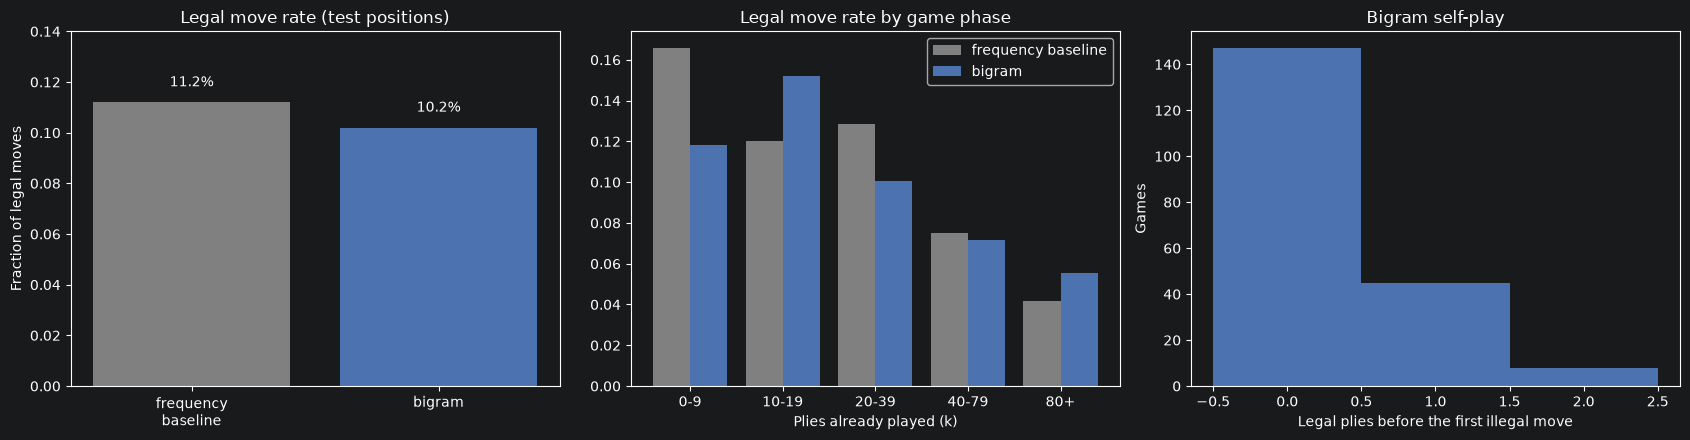

Longest legal self-play game (2 plies): e4 Nc6


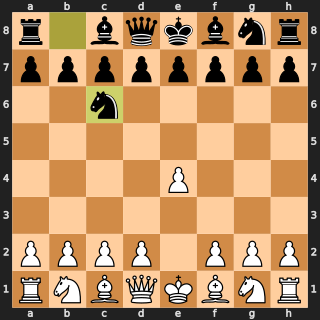

In [11]:
# --- NEXT-MOVE LEGALITY ON THE 1,000 TEST POSITIONS ---

# Fixed seeds for reproducibility of the sampling.
np.random.seed(0)

# Same for Python's random module.
random.seed(0)

# Start time.
start = time.perf_counter()

# Baseline.
rate_base, res_base = evaluate_legality(frequency_baseline)

# Bigram at temperature 1.
rate_bigram, res_bigram = evaluate_legality(char_model_proposer(bigram_next_char_probs))

# Report.
print(f"Legal move rate on 1,000 test positions ({time.perf_counter() - start:.0f}s):")

# Baseline.
print(f"  frequency baseline (no context): {rate_base:.1%}")

# Bigram.
print(f"  bigram (temperature 1):          {rate_bigram:.1%}")

# --- RATE BY GAME PHASE ---

# Bins of the cut point k (number of plies already played).
PHASE_BINS = [(0, 10), (10, 20), (20, 40), (40, 80), (80, 10_000)]

# Readable labels.
PHASE_LABELS = ["0-9", "10-19", "20-39", "40-79", "80+"]


# Legal rate within each phase bin.
def rate_by_phase(results):
    """results: list of (k, legal). Returns one legal rate per bin (NaN if a bin is empty)."""

    # One value per bin.
    rates = []

    # Go through the bins.
    for lo, hi in PHASE_BINS:

        # Legality of the positions whose k falls in [lo, hi).
        in_bin = [legal for k, legal in results if lo <= k < hi]

        # Mean, or NaN for an empty bin.
        rates.append(np.mean(in_bin) if in_bin else np.nan)

    # Return the list.
    return rates


# --- SELF-PLAY ---

# 200 games of the bigram against itself.
bigram_plies, bigram_sequences = self_play(bigram_next_char_probs, n_games=200)

# Summary.
print(f"\nSelf-play (200 games): mean {np.mean(bigram_plies):.2f} legal plies before the first error, max {max(bigram_plies)}")

# --- PLOTS ---

# Three panels.
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(17, 4.5))

# Panel 1: overall legal move rate.
bars = ax1.bar(["frequency\nbaseline", "bigram"], [rate_base, rate_bigram], color=["gray", "#4C72B0"])

# Write the values on top of the bars.
for bar, value in zip(bars, [rate_base, rate_bigram]):

    # Centre of the bar, slightly above its top.
    ax1.text(bar.get_x() + bar.get_width() / 2, value + 0.005, f"{value:.1%}", ha="center", va="bottom")

# Title.
ax1.set_title("Legal move rate (test positions)")

# y-axis label.
ax1.set_ylabel("Fraction of legal moves")

# Leave 25% of empty space above the tallest bar, so the labels do not overlap the title.
ax1.set_ylim(0, max(rate_base, rate_bigram) * 1.25)

# Panel 2: rate by phase.
x = np.arange(len(PHASE_LABELS))

# Baseline bars (shifted left).
ax2.bar(x - 0.2, rate_by_phase(res_base), width=0.4, color="gray", label="frequency baseline")

# Bigram bars (shifted right).
ax2.bar(x + 0.2, rate_by_phase(res_bigram), width=0.4, color="#4C72B0", label="bigram")

# Phase labels on the x-axis.
ax2.set_xticks(x, PHASE_LABELS)

# x-axis label.
ax2.set_xlabel("Plies already played (k)")

# Title.
ax2.set_title("Legal move rate by game phase")

# Legend.
ax2.legend()

# Panel 3: histogram of legal plies in self-play; bins of width 1.
ax3.hist(bigram_plies, bins=range(0, max(bigram_plies) + 2), color="#4C72B0", align="left")

# x-axis label.
ax3.set_xlabel("Legal plies before the first illegal move")

# y-axis label.
ax3.set_ylabel("Games")

# Title.
ax3.set_title("Bigram self-play")

# Avoid overlapping labels.
plt.tight_layout()

# Render the figure.
plt.show()

# --- THE LONGEST LEGAL SELF-PLAY GAME ---

# Index of the game with the most legal plies.
best = int(np.argmax(bigram_plies))

# Its moves.
best_moves = bigram_sequences[best]

# Print them.
print(f"Longest legal self-play game ({len(best_moves)} plies):", " ".join(best_moves))

# Replay it on a board.
board = chess.Board()

# One move at a time.
for m in best_moves:

    # Play the move.
    board.push_san(m)

# Draw the final position; lastmove highlights the last move played (if any).
display(SVG(chess.svg.board(board, lastmove=board.peek() if best_moves else None, size=320)))

## Step 10 — What the bigram can and cannot do

**What it learned:**
- the **shape** of SAN: piece letters are followed by files, files by ranks, then a space;
- the **statistics** of characters: `e` and `d` are common files, `x` is followed by a file, and so on.

**What it cannot do:**
- remember **which move it is writing**: after `N`, it does not know whether it already wrote the file;
- know **where the pieces are**: that requires remembering the whole game, not one character.

This is why its moves are legal only when they happen to match the position by luck.

### Saving the results for the comparison across versions
We store the key numbers in a small JSON file. Every later version will add its own line, and v6 will draw the final comparison chart from it.

### Next: v2
An **MLP** that looks at the last $n$ characters through learned **embeddings** (Bengio et al., 2003). With a few characters of context, it can at least know which part of the move it is writing.

In [12]:
# --- SAVE THE RESULTS OF v1 ---

# Standard-library JSON module.
import json

# File shared by all versions of ChessGPT.
RESULTS_PATH = DATA_DIR / "chessgpt_results.json"

# Load the existing results, if any, otherwise start an empty dictionary.
results_all = json.loads(RESULTS_PATH.read_text()) if RESULTS_PATH.exists() else {}

# Results of the frequency baseline.
results_all["baseline"] = {"legal_rate": float(rate_base)}

# Results of the bigram.
results_all["v1_bigram"] = {
    # Validation bits per character.
    "val_bpc": float(nll_count / np.log(2)),
    # Legal move rate on the 1,000 test positions.
    "legal_rate": float(rate_bigram),
    # Average legal plies in self-play.
    "selfplay_mean_plies": float(np.mean(bigram_plies)),
}

# Write the file, indented for readability.
RESULTS_PATH.write_text(json.dumps(results_all, indent=2))

# Show what was saved.
print(json.dumps(results_all, indent=2))

{
  "baseline": {
    "legal_rate": 0.112
  },
  "v1_bigram": {
    "val_bpc": 2.4304427985659216,
    "legal_rate": 0.102,
    "selfplay_mean_plies": 0.305
  }
}


## Results and conclusions

### Data
- **115,628 games** kept from 121,332 (5,704 shorter than 20 plies), 33.4 million characters.
- On average 70 plies per game and 4.14 characters per ply (spaces included).
- **7,443 distinct SAN moves.** The most common opening is `e4 e5` (27% of games).
- Lichess adds annotations (`!`, `?`, `?!`) to analysed games; they are removed during cleaning, leaving a vocabulary of **29 characters**.

### Language modelling
| Model | NLL (nats) | Perplexity | Bits per char |
|---|---|---|---|
| Uniform guess | 3.367 | 29.00 | 4.858 |
| Bigram (counting) | 1.685 | 5.39 | **2.430** |
| Bigram (neural) | 1.686 | 5.40 | 2.432 |

- The bigram **halves** the uncertainty per character compared with a uniform guess.
- Gradient descent **rediscovers the counting solution** (maximum difference 0.02, only on rare pairs where Laplace smoothing matters).
- The heatmap shows the **grammar of SAN** learned from data alone: file → rank → space / `+` / `#`; piece → file or `x`; `O` → `-`; `=` → piece; and `#` → `;`, i.e. *checkmate ends the game*.

### Chess legality
| Model | Legal move rate (1,000 test positions) | Self-play: legal plies |
|---|---|---|
| Frequency baseline (no context) | 11.2% | — |
| Bigram | **10.2%** | 0.30 on average (max 2) |

- **The bigram does not beat the baseline**: the difference is within statistical noise (±1 point).
  The baseline always outputs a *real* move such as `Nf3`, while the bigram builds moves character by character without remembering what it just wrote, producing malformed strings such as `Bxdxe6` or `Kcxf5`.
- In self-play, 147 of 200 games fail **on the very first move**.
- Both models get worse as the game progresses: common moves are often legal in the opening, almost never in the endgame.

### Conclusion
One character of context is enough to learn the *alphabet and grammar* of SAN, but not to write well-formed moves, let alone legal ones.
The model needs **more context**: at least the current move, ideally the whole game.

### Next: v2
An MLP that sees the last several characters through learned **embeddings** (Bengio et al., 2003). It should at least write well-formed moves, and start to beat the baseline.